<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Clase 3, Vóxeles y CNN 3D (versión liviana)**

1. voxelizamos objetos reales de ModelNet10
2. entrenamos una CNN 3D densa pequeña
3. vemos sus predicciones y dónde mira con Grad-CAM 3D

esta versión está pensada para correr rápido, incluso sin GPU:
* ModelNet10 en lugar de ModelNet40: 10 clases de muebles y objetos de casa, unos 4 mil objetos en lugar de 12 mil
* ModelNet10 es un subconjunto de ModelNet40, así que lo sacamos del mismo archivo, filtrando las 10 clases
* la red tiene 8, 16 y 32 canales en lugar de 32, 64 y 128, eso deja unas 15 veces menos parámetros

---
## **1.- Importamos lo necesario**

In [1]:
import time
import glob
import zipfile
import h5py
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download

usamos la GPU si hay una, si no, la CPU

In [2]:
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print("usando:", dispositivo)

usando: cpu


descargamos el zip de ModelNet40 y lo descomprimimos

In [3]:
zipfile.ZipFile(hf_hub_download("Msun/modelnet40", "modelnet40_ply_hdf5_2048.zip", repo_type="dataset")).extractall(".")

modelnet40_ply_hdf5_2048.zip: reconstructing file:   0%|          |  0.00B /  435MB            

modelnet40_ply_hdf5_2048.zip: downloading bytes:           |  0.00B            

## **2.- Nos quedamos con las 10 clases de ModelNet10**

leemos los 40 nombres y buscamos la posición de las 10 clases que forman ModelNet10

In [4]:
TODAS = open("modelnet40_ply_hdf5_2048/shape_names.txt").read().split()
CLASES = ["bathtub", "bed", "chair", "desk", "dresser", "monitor", "night_stand", "sofa", "table", "toilet"]
IDS = np.array([TODAS.index(c) for c in CLASES])  # etiqueta que cada clase tiene en ModelNet40
print(IDS)

[ 1  2  8 12 14 22 23 30 33 35]


la siguiente función:
* recibe train o test
* lee todos los archivos de ese conjunto y se queda con los primeros 1024 puntos de cada objeto
* descarta los objetos que no son de las 10 clases
* renumera las etiquetas de 0 a 9, porque cross entropy espera etiquetas seguidas
* convierte todo a tensores y lo manda al dispositivo

In [5]:
def leer(split):
    archivos = sorted(glob.glob(f"modelnet40_ply_hdf5_2048/ply_data_{split}*.h5"))
    X = np.concatenate([h5py.File(f)["data"][:, :1024] for f in archivos])
    y = np.concatenate([h5py.File(f)["label"][:].ravel() for f in archivos])
    quedan = np.isin(y, IDS)                   # True para los objetos de las 10 clases
    y = np.searchsorted(IDS, y[quedan])        # pasa la etiqueta de ModelNet40 a su posición en CLASES (0 a 9)
    return torch.tensor(X[quedan]).to(dispositivo), torch.tensor(y).long().to(dispositivo)

In [6]:
Xtr, ytr = leer("train")
Xte, yte = leer("test")
print("entrenamiento:", tuple(Xtr.shape), "| test:", tuple(Xte.shape))

entrenamiento: (3991, 1024, 3) | test: (908, 1024, 3)


contamos cuántos objetos hay por clase, el conjunto no está balanceado: hay muchas más sillas que bañeras

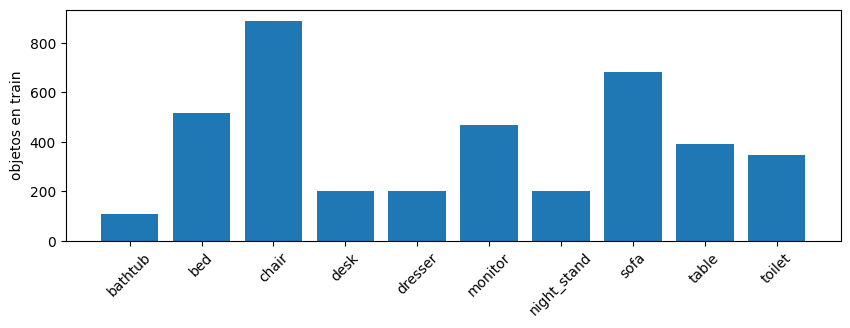

In [7]:
cuenta = torch.bincount(ytr, minlength=10).cpu()
plt.figure(figsize=(10, 3))
plt.bar(CLASES, cuenta)
plt.xticks(rotation=45); plt.ylabel("objetos en train")
plt.show()

## **3.- Voxelizar**

esta función recibe:
* P, un lote de B objetos con N puntos de 3 coordenadas cada uno
* R, cantidad de cubos por lado

devuelve una grilla por objeto, con 1 donde cae algún punto y 0 en el resto

In [8]:
def voxelizar(P, R):
    i = ((P + 1) / 2 * R).long().clamp(0, R - 1)              # de [-1, 1] a número de cubo entre 0 y R - 1
    V = torch.zeros(len(P), 1, R, R, R, device=P.device)       # grilla vacía, una por objeto
    b = torch.arange(len(P), device=P.device)[:, None]         # a qué objeto del lote pertenece cada punto
    V[b, 0, i[..., 0], i[..., 1], i[..., 2]] = 1               # marca los cubos ocupados, todos a la vez y sin bucles
    return V

vemos un objeto a tres resoluciones

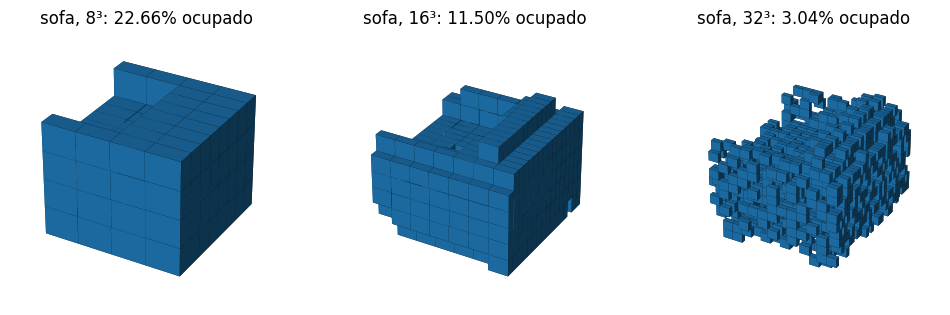

In [9]:
fig = plt.figure(figsize=(12, 4))
for k, R in enumerate([8, 16, 32]):
    V = voxelizar(Xtr[:1], R)[0, 0].cpu().numpy().astype(bool)
    ax = fig.add_subplot(1, 3, k + 1, projection="3d"); ax.set_axis_off()
    ax.voxels(V.transpose(0, 2, 1), edgecolor="k", linewidth=0.05)
    ax.set_title(f"{CLASES[ytr[0]]}, {R}³: {V.mean():.2%} ocupado")
plt.show()

* a 8³ el objeto apenas se reconoce, a 32³ ya se ve bien la forma
* entrenamos a 32³, que es un buen equilibrio entre detalle y costo

In [10]:
R = 32

## **4.- CNN 3D densa pequeña**

la misma idea que una CNN 2D con un eje más: filtros de 3 × 3 × 3 y pooling de 2 × 2 × 2, voxelizamos cada lote al vuelo

esta función aumenta los datos, deforma un poco cada objeto en cada lote

In [11]:
def aumentar(P):
    return (P * torch.empty(len(P), 1, 3, device=P.device).uniform_(0.8, 1.2)    # escala al azar por eje, entre 80 % y 120 %
              + torch.empty(len(P), 1, 3, device=P.device).uniform_(-0.1, 0.1)).clamp(-1, 1)  # desplaza al azar y recorta a [-1, 1]

bucle de entrenamiento: en cada época mezcla, entrena por lotes y mide el accuracy en test

In [12]:
def entrenar(red, modulos, epocas=10, lote=32):
    opt = torch.optim.Adam(modulos.parameters(), lr=1e-3)
    if dispositivo == "cuda":
        torch.cuda.reset_peak_memory_stats()   # reinicia el medidor de memoria
    t0 = time.time()
    for epoca in range(epocas):
        modulos.train()
        for b in torch.randperm(len(Xtr), device=dispositivo).split(lote):   # mezcla los índices y los corta en lotes
            perdida = F.cross_entropy(red(aumentar(Xtr[b])), ytr[b])        # aumenta, predice y calcula el error
            opt.zero_grad()
            perdida.backward()
            opt.step()

        modulos.eval()
        with torch.no_grad():
            acc = torch.cat([red(x).argmax(1) for x in Xte.split(64)]).eq(yte).float().mean()
        print(f"época {epoca + 1:2d} | pérdida {perdida.item():.3f} | accuracy test {acc:.3f}")
    print(f"{(time.time() - t0) / epocas:.1f} s por época")
    if dispositivo == "cuda":
        print(f"memoria máxima {torch.cuda.max_memory_allocated() / 1024**2:.0f} MB")

bloque básico: convolución, normalización, activación y reducción

In [13]:
def bloque(cin, cout):
    return [nn.Conv3d(cin, cout, 3, padding=1),
            nn.BatchNorm3d(cout),
            nn.ReLU(),
            nn.MaxPool3d(2)]

tres bloques: 32³ -> 16³ -> 8³ -> 4³, con 8, 16 y 32 canales

In [14]:
cnn = nn.Sequential(*bloque(1, 8),
                    *bloque(8, 16),
                    *bloque(16, 32),
                    nn.AdaptiveMaxPool3d(1),   # un valor por canal, el máximo de toda la grilla
                    nn.Flatten(),
                    nn.Dropout(0.3),
                    nn.Linear(32, 10)).to(dispositivo)

contamos los parámetros y los comparamos con la red de 32, 64 y 128 canales que clasificaba 40 clases

In [15]:
grande = nn.Sequential(*bloque(1, 32), *bloque(32, 64), *bloque(64, 128), nn.Linear(128, 40))
contar = lambda m: sum(p.numel() for p in m.parameters())
print(f"red pequeña: {contar(cnn):,} parámetros | red grande: {contar(grande):,} parámetros")

red pequeña: 17,994 parámetros | red grande: 283,176 parámetros


recibe puntos, los voxeliza a 32³ y los pasa por la CNN

In [16]:
densa = lambda P: cnn(voxelizar(P, R))

entrenamos e imprimimos los resultados

In [17]:
entrenar(densa, cnn)

época  1 | pérdida 1.684 | accuracy test 0.587
época  2 | pérdida 1.073 | accuracy test 0.688
época  3 | pérdida 0.972 | accuracy test 0.778
época  4 | pérdida 0.783 | accuracy test 0.819
época  5 | pérdida 0.598 | accuracy test 0.794
época  6 | pérdida 0.484 | accuracy test 0.844
época  7 | pérdida 0.478 | accuracy test 0.831
época  8 | pérdida 0.319 | accuracy test 0.860
época  9 | pérdida 0.353 | accuracy test 0.857
época 10 | pérdida 0.457 | accuracy test 0.862
65.8 s por época


**Matriz de confusión**

muestra qué clases confunde la red, las filas son la clase real y las columnas la predicha

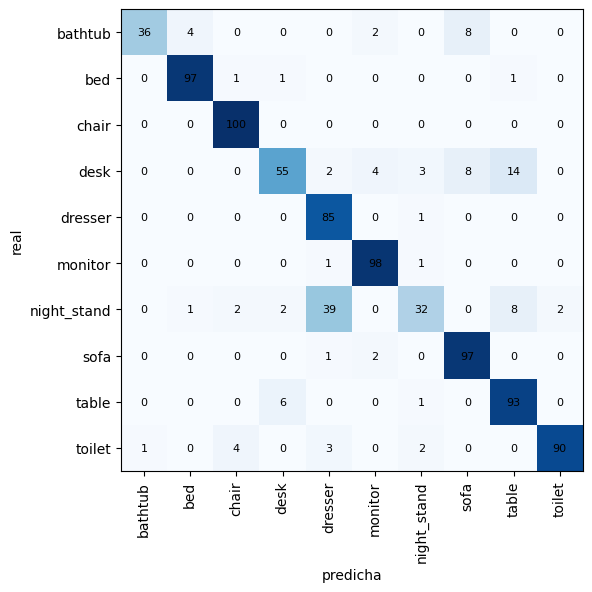

In [18]:
cnn.eval()
with torch.no_grad():
    pred = torch.cat([densa(x).argmax(1) for x in Xte.split(64)])
M = torch.zeros(10, 10, dtype=torch.long)
for r, p in zip(yte.cpu(), pred.cpu()):
    M[r, p] += 1

plt.figure(figsize=(6, 6))
plt.imshow(M, cmap="Blues")
plt.xticks(range(10), CLASES, rotation=90); plt.yticks(range(10), CLASES)
for r in range(10):
    for p in range(10):
        plt.text(p, r, M[r, p].item(), ha="center", va="center", fontsize=8)
plt.xlabel("predicha"); plt.ylabel("real")
plt.show()

lo esperable es que se confundan desk con table y dresser con night_stand, que a 32³ tienen formas muy parecidas

**Predicciones en 8 objetos de test**

tomamos 8 objetos al azar y dibujamos cada uno en verde si acertó o en rojo si falló, con la clase real y las 3 más probables

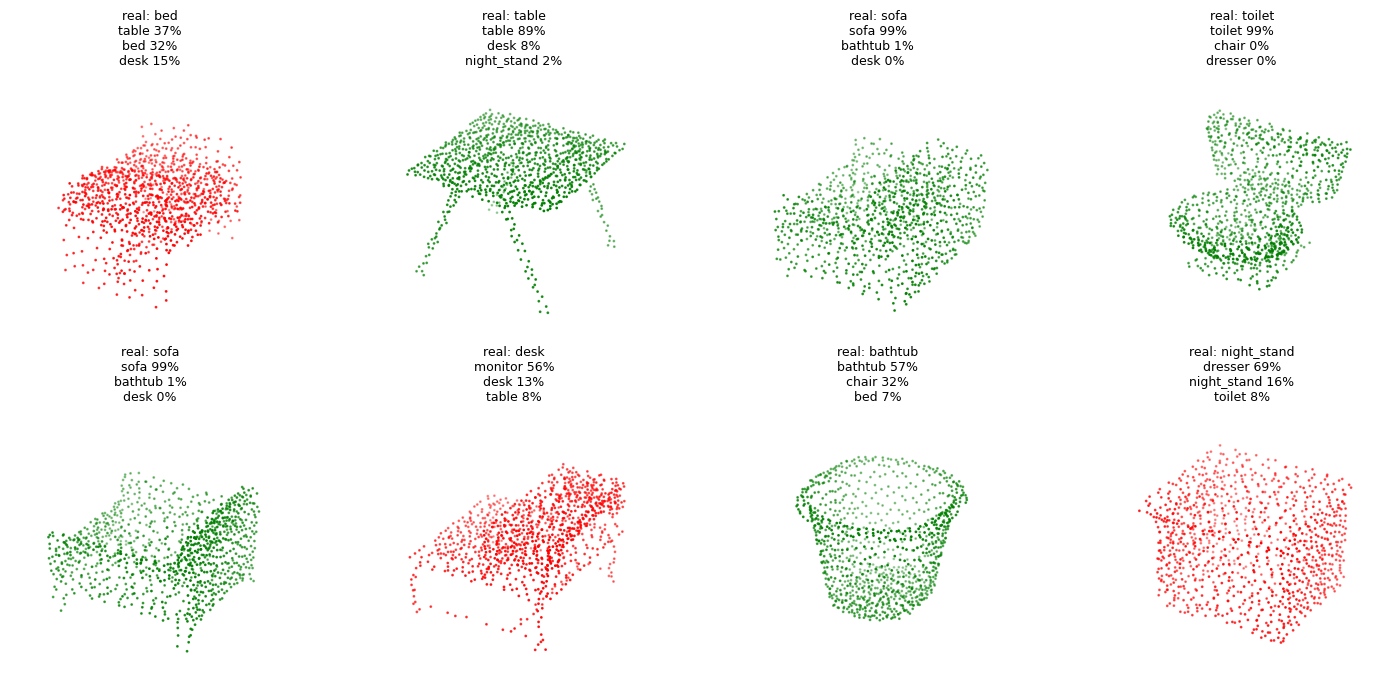

In [19]:
ejemplos = torch.randperm(len(Xte))[:8]
with torch.no_grad():
    prob = F.softmax(densa(Xte[ejemplos]), dim=1)

fig = plt.figure(figsize=(18, 8))
for k, i in enumerate(ejemplos):
    p = Xte[i].cpu()
    top_p, top_c = prob[k].topk(3)
    acierto = top_c[0] == yte[i]
    ax = fig.add_subplot(2, 4, k + 1, projection="3d"); ax.set_axis_off()
    ax.scatter(p[:, 0], p[:, 2], p[:, 1], s=1, c="green" if acierto else "red")
    ax.set_title(f"real: {CLASES[yte[i]]}\n" + "\n".join(f"{CLASES[c]} {v:.0%}" for v, c in zip(top_p, top_c)), fontsize=9)
plt.show()

**Grad-CAM 3D**

calcula qué puntos de cada objeto pesaron más en la decisión y los pinta de oscuro (poco importante) a claro (muy importante)

In [20]:
def donde_mira(P):
    V = voxelizar(P[None], R)                         # agrega la dimensión de lote y voxeliza
    f = cnn[:11](V); f.retain_grad()                  # corre la red hasta la última convolución (8³) y guarda su gradiente
    salida = cnn[11:](f); c = salida.argmax()         # corre el resto y toma la clase predicha
    salida[0, c].backward()                           # cuánto influye cada mapa en el puntaje de esa clase
    cam = F.relu((f.grad.mean(dim=(2, 3, 4), keepdim=True) * f).sum(1, keepdim=True))  # pesa cada canal por su gradiente promedio
    cam = F.interpolate(cam, size=R, mode="trilinear")[0, 0].detach()                  # agranda de 8³ a 32³
    i = ((P + 1) / 2 * R).long().clamp(0, R - 1)                                       # vóxel de cada punto
    return cam[i[:, 0], i[:, 1], i[:, 2]].cpu(), c.item()

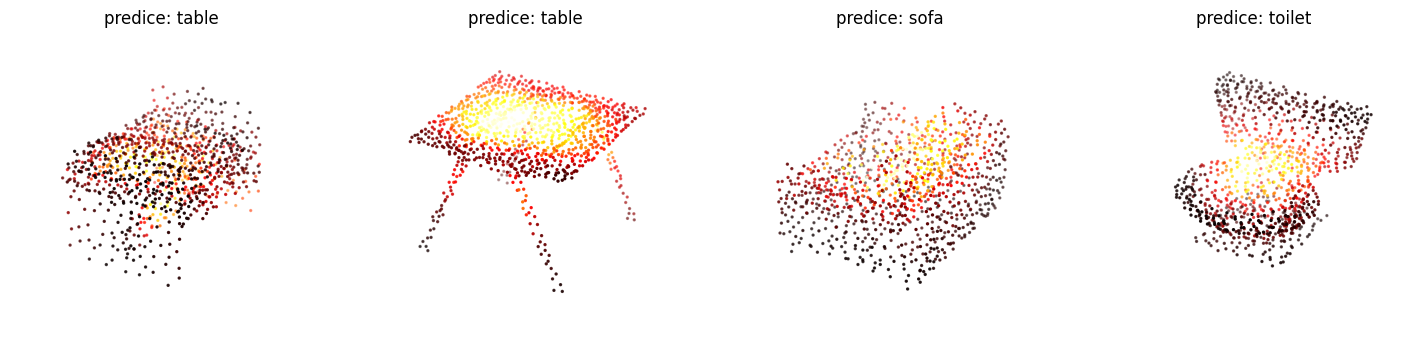

In [21]:
fig = plt.figure(figsize=(18, 4.5))
for k, i in enumerate(ejemplos[:4]):
    imp, c = donde_mira(Xte[i])
    p = Xte[i].cpu()
    ax = fig.add_subplot(1, 4, k + 1, projection="3d"); ax.set_axis_off()
    ax.scatter(p[:, 0], p[:, 2], p[:, 1], s=2, c=imp, cmap="hot")
    ax.set_title(f"predice: {CLASES[c]}")
plt.show()

* con 10 clases el problema es más fácil, por eso una red de unos 18 mil parámetros alcanza para aprender bien las formas
* la red pequeña entrena en pocos segundos por época en GPU y se puede correr en CPU
* la limitación sigue siendo la misma: voxelizar pierde el detalle dentro de cada cubo, y una grilla densa gasta memoria en cubos vacíos